TEXT PREPROCESSING AND EDA

In [10]:
import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ARYAN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ARYAN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ARYAN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [13]:
import pandas as pd, re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

df = pd.read_csv("../data/resumes_cleaned.csv")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

custom_stop = {
    "exprience", "experience", "company", "description", "detail", "detailsdescription",
    "month", "year", "less", "skill", "education", "responsibility", "work", "worked", "working"
}

custom_stop |= {
    "maharashtra", "mumbai", "pune", "nagpur", "india",
    "january", "february", "march", "april", "may", "june", "july",
    "august", "september", "october", "november", "december",
    "like", "using", "form"
}

def preprocess(text):
    tokens = re.findall(r"[a-z0-9+#.]+", text.lower())
    tokens = [t.strip(".") for t in tokens]
    tokens = [t for t in tokens if t and t not in stop_words and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    tokens = [t for t in tokens
              if t not in custom_stop and not t.startswith(("month", "year"))]
    return " ".join(tokens)

df["processed"] = df["clean_resume"].apply(preprocess)
df[["Category", "processed"]].to_csv("../data/resumes_processed.csv", index=False)

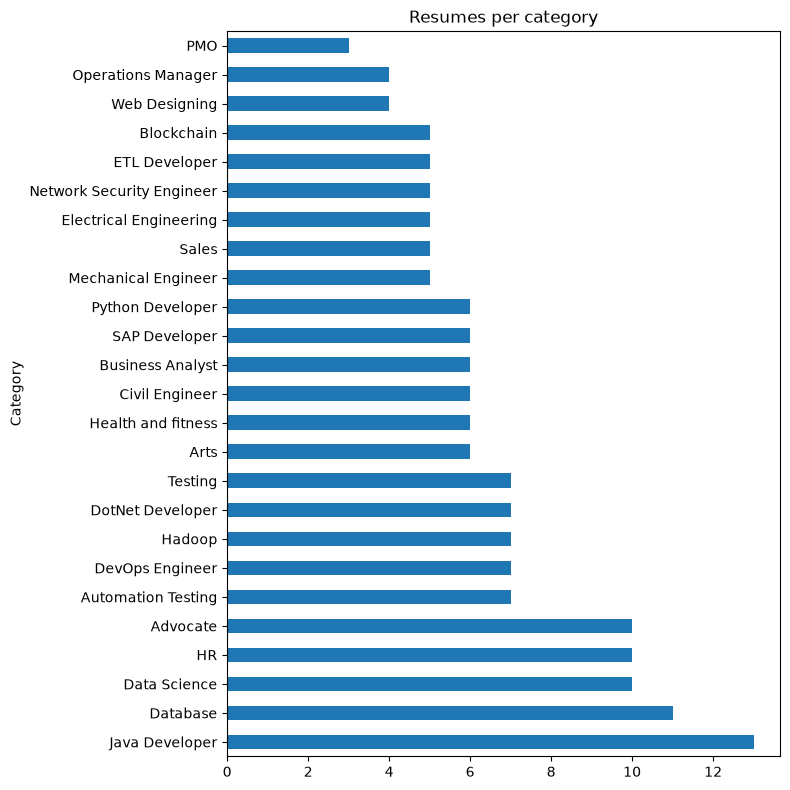

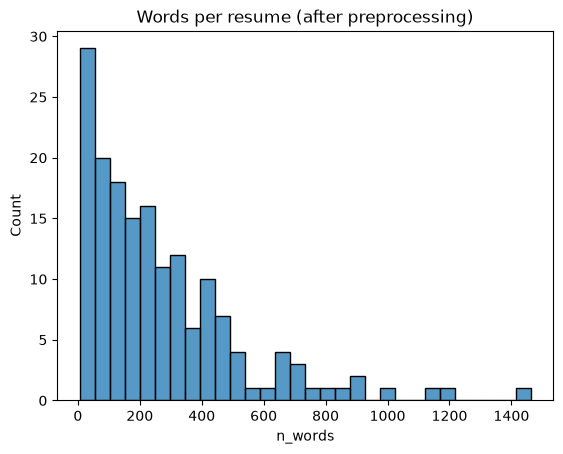

[('project', 624), ('data', 390), ('database', 345), ('system', 325), ('management', 320), ('team', 304), ('server', 253), ('sql', 235), ('client', 224), ('test', 223), ('technology', 216), ('business', 216), ('testing', 216), ('report', 211), ('service', 205), ('requirement', 202), ('developer', 196), ('application', 194), ('ltd', 191), ('development', 183), ('java', 176), ('customer', 169), ('user', 166), ('role', 163), ('engineering', 162)]
[('data', 99), ('learning', 50), ('python', 44), ('science', 43), ('machine', 40), ('analytics', 30), ('project', 24), ('analysis', 21), ('sql', 18), ('deep', 18), ('technology', 18), ('business', 18), ('model', 17), ('sap', 17), ('platform', 16)]
[('hr', 20), ('management', 15), ('employee', 10), ('payroll', 7), ('engineering', 6), ('university', 6), ('salary', 6), ('computer', 6), ('mba', 5), ('college', 5), ('software', 5), ('statutory', 5), ('compliance', 5), ('dynamic', 5), ('2017', 4)]


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# a) Class distribution
plt.figure(figsize=(8, 8))
df["Category"].value_counts().plot(kind="barh")
plt.title("Resumes per category"); plt.tight_layout(); plt.show()

# b) Resume length distribution
df["n_words"] = df["processed"].str.split().str.len()
sns.histplot(df["n_words"], bins=30)
plt.title("Words per resume (after preprocessing)"); plt.show()

# c) Top words overall
counts = Counter(" ".join(df["processed"]).split())
print(counts.most_common(25))

# d) Top words for one category
def top_words(cat, n=15):
    words = " ".join(df[df["Category"] == cat]["processed"]).split()
    return Counter(words).most_common(n)

print(top_words("Data Science"))
print(top_words("HR"))